# UTS Machine Learning — Prediksi Produksi Lada dengan Regresi Linier

## Soal 1 — Pengenalan dan Pengolahan Dataset

In [1]:
#202431035_Fawwaz Marzuqi Saputra
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

file = "23_Jumlah_Produksi_Lada_1.xlsx"

# Baris provinsi dimulai dari baris ke-12; kolom B = provinsi, AC = 2023, AD = 2024
# na_values=["-"] membuat tanda "-" terbaca sebagai NaN (bukan teks)
df = pd.read_excel(file, header=None, skiprows=11, nrows=38,
                   usecols="B,AC,AD", na_values=["-"])
df.columns = ["provinsi", "x_2023", "y_2024"]

print("Ukuran data :", df.shape)
print("Missing value per kolom:")
print(df.isna().sum())
print("Provinsi dengan produksi 0 -> 2023:", (df["x_2023"] == 0).sum(),
      "| 2024:", (df["y_2024"] == 0).sum())

Ukuran data : (38, 3)
Missing value per kolom:
provinsi    0
x_2023      0
y_2024      0
dtype: int64
Provinsi dengan produksi 0 -> 2023: 9 | 2024: 10


In [2]:
#202431035_Fawwaz Marzuqi Saputra

# Data Preparation
# Missing value: imputasi konstan 0 (jika ada sel kosong / "-")
df = df.fillna(0)

# Ambil 15 provinsi sampel, nilai dibulatkan agar sama dengan hitungan manual
sampel = df.head(15).copy()
sampel["X"] = sampel["x_2023"].round().astype(int)
sampel["Y"] = sampel["y_2024"].round().astype(int)
sampel = sampel[["provinsi", "X", "Y"]]
sampel

                     provinsi      X      Y
0                        Aceh    258    254
1              Sumatera Utara    268    279
2              Sumatera Barat      9      9
3                        Riau      0      0
4                       Jambi     11     11
5            Sumatera Selatan   4833   4875
6                    Bengkulu   1116   1429
7                     Lampung  13910  15791
8   Kepulauan Bangka Belitung  18454  12009
9              Kepulauan Riau     45     32
10                DKI Jakarta      0      0
11                 Jawa Barat    840    862
12                Jawa Tengah    551    583
13              DI Yogyakarta      4      6
14                 Jawa Timur    184    148

In [3]:
#202431035_Fawwaz Marzuqi Saputra
# Deteksi outlier dengan IQR (posisi kuartil (n+1)p, sama dengan hitungan manual)
def batas_iqr(s):
    q1, q3 = np.percentile(s, [25, 75], method="weibull")
    iqr = q3 - q1
    return q1, q3, iqr, q3 + 1.5 * iqr

for k in ["X", "Y"]:
    q1, q3, iqr, batas_atas = batas_iqr(sampel[k])
    outlier = sampel.loc[sampel[k] > batas_atas, "provinsi"].tolist()
    print(f"{k}: Q1={q1:,.0f} | Q3={q3:,.0f} | IQR={iqr:,.0f} | Batas atas={batas_atas:,.1f}")
    print("   Outlier:", outlier)

X: Q1=9 | Q3=1,116 | IQR=1,107 | Batas atas=2,776.5
   Outlier: ['Sumatera Selatan', 'Lampung', 'Kepulauan Bangka Belitung']
Y: Q1=9 | Q3=1,429 | IQR=1,420 | Batas atas=3,559.0
   Outlier: ['Sumatera Selatan', 'Lampung', 'Kepulauan Bangka Belitung']


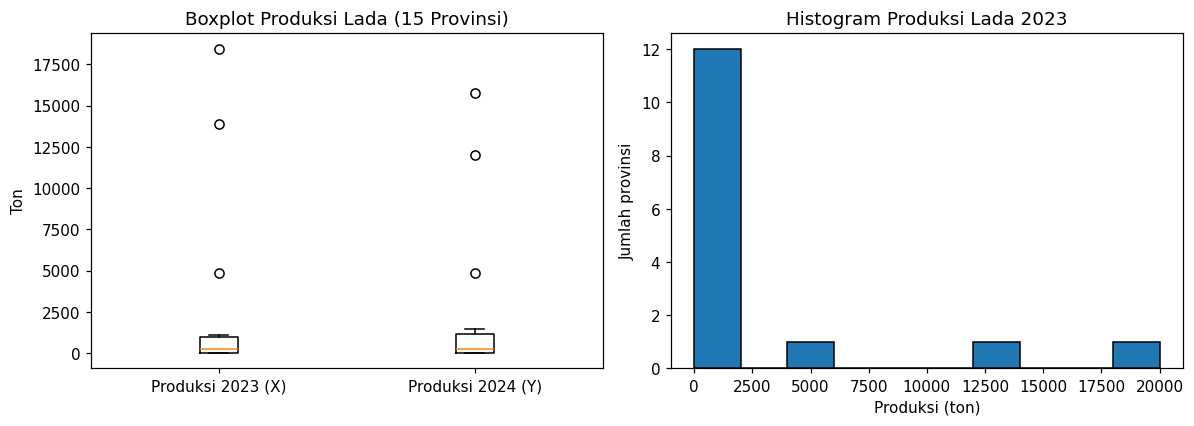

In [4]:
#202431035_Fawwaz Marzuqi Saputra
# Visualisasi: boxplot dan histogram
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].boxplot([sampel["X"], sampel["Y"]], tick_labels=["Produksi 2023 (X)", "Produksi 2024 (Y)"])
ax[0].set_title("Boxplot Produksi Lada (15 Provinsi)")
ax[0].set_ylabel("Ton")

ax[1].hist(sampel["X"], bins=range(0, 20001, 2000), edgecolor="black")
ax[1].set_title("Histogram Produksi Lada 2023")
ax[1].set_xlabel("Produksi (ton)")
ax[1].set_ylabel("Jumlah provinsi")

plt.tight_layout()
plt.savefig("eda_boxplot_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

## Soal 3 — Implementasi Regresi Linier (Python)

In [5]:
#202431035_Fawwaz Marzuqi Saputra
# Proses Modeling (fitting Regresi Linier)
X = sampel[["X"]]          # fitur: produksi 2023
y = sampel["Y"]            # target: produksi 2024

model = LinearRegression()
model.fit(X, y)

print("Slope     (b) :", round(model.coef_[0], 4))
print("Intercept (a) :", round(model.intercept_, 2))
print(f"Persamaan     : Y = {model.intercept_:.2f} + {model.coef_[0]:.4f} X")

Slope     (b) : 0.8205
Intercept (a) : 204.72
Persamaan     : Y = 204.72 + 0.8205 X


In [6]:
#202431035_Fawwaz Marzuqi Saputra
# Evaluasi performa model
y_pred = model.predict(X)
galat  = y - y_pred

r2   = model.score(X, y)
mae  = np.mean(np.abs(galat))
rmse = np.sqrt(np.mean(galat ** 2))
wape = np.sum(np.abs(galat)) / np.sum(y) * 100      # error relatif terhadap total produksi

# MAPE tidak terdefinisi jika nilai aktual = 0, jadi hanya provinsi dengan Y > 0
nol  = y > 0
mape = np.mean(np.abs(galat[nol]) / y[nol]) * 100

print(f"R-squared : {r2:.4f}")
print(f"MAE       : {mae:,.2f} ton")
print(f"RMSE      : {rmse:,.2f} ton")
print(f"WAPE      : {wape:.2f} %   (target bisnis < 15 %)")
print(f"MAPE      : {mape:.2f} %   (hanya {nol.sum()} provinsi dengan Y > 0)")

R-squared : 0.9114
MAE       : 691.48 ton
RMSE      : 1,402.19 ton
WAPE      : 28.58 %   (target bisnis < 15 %)
MAPE      : 652.67 %   (hanya 13 provinsi dengan Y > 0)


In [7]:
#202431035_Fawwaz Marzuqi Saputra
# Perbandingan hasil manual vs program
b_manual, a_manual = 0.8205, 204.72
print("Manual  : a =", a_manual, "| b =", b_manual)
print("Program : a =", round(model.intercept_, 2), "| b =", round(model.coef_[0], 4))

hasil = sampel.copy()
hasil["Prediksi_Y"] = y_pred.round(1)
hasil["Galat"] = galat.round(1)
hasil

Manual  : a = 204.72 | b = 0.8205
Program : a = 204.72 | b = 0.8205


                     provinsi      X      Y  Prediksi_Y   Galat
0                        Aceh    258    254       416.4  -162.4
1              Sumatera Utara    268    279       424.6  -145.6
2              Sumatera Barat      9      9       212.1  -203.1
3                        Riau      0      0       204.7  -204.7
4                       Jambi     11     11       213.7  -202.7
5            Sumatera Selatan   4833   4875      4170.3   704.7
6                    Bengkulu   1116   1429      1120.4   308.6
7                     Lampung  13910  15791     11618.2  4172.8
8   Kepulauan Bangka Belitung  18454  12009     15346.6 -3337.6
9              Kepulauan Riau     45     32       241.6  -209.6
10                DKI Jakarta      0      0       204.7  -204.7
11                 Jawa Barat    840    862       894.0   -32.0
12                Jawa Tengah    551    583       656.8   -73.8
13              DI Yogyakarta      4      6       208.0  -202.0
14                 Jawa Timur    184    

In [8]:
#202431035_Fawwaz Marzuqi Saputra
# Prediksi produksi 2025: model dipakai dengan X = produksi 2024
x_2024 = pd.DataFrame({"X": sampel["Y"].values})
prediksi_2025 = model.predict(x_2024)

p2025 = pd.DataFrame({"provinsi": sampel["provinsi"],
                      "Produksi_2024": sampel["Y"],
                      "Prediksi_2025": prediksi_2025.round(1)})
print(p2025.to_string(index=False))
print("\nTotal prediksi 2025 (15 provinsi):", round(prediksi_2025.sum(), 1), "ton")

                 provinsi  Produksi_2024  Prediksi_2025
                     Aceh            254          413.1
           Sumatera Utara            279          433.6
           Sumatera Barat              9          212.1
                     Riau              0          204.7
                    Jambi             11          213.7
         Sumatera Selatan           4875         4204.8
                 Bengkulu           1429         1377.2
                  Lampung          15791        13161.6
Kepulauan Bangka Belitung          12009        10058.4
           Kepulauan Riau             32          231.0
              DKI Jakarta              0          204.7
               Jawa Barat            862          912.0
              Jawa Tengah            583          683.1
            DI Yogyakarta              6          209.6
               Jawa Timur            148          326.2

Total prediksi 2025 (15 provinsi): 32845.9 ton


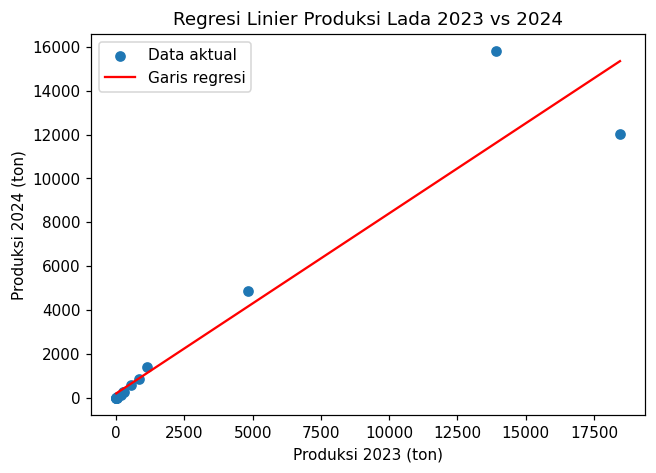

In [9]:
#202431035_Fawwaz Marzuqi Saputra
# Plot garis regresi
plt.figure(figsize=(6.5, 4.5))
plt.scatter(sampel["X"], sampel["Y"], label="Data aktual")
xs = np.linspace(0, sampel["X"].max(), 100).reshape(-1, 1)
plt.plot(xs, model.predict(pd.DataFrame(xs, columns=["X"])), color="red", label="Garis regresi")
plt.xlabel("Produksi 2023 (ton)")
plt.ylabel("Produksi 2024 (ton)")
plt.title("Regresi Linier Produksi Lada 2023 vs 2024")
plt.legend()
plt.show()